# 01 · Inspect the word table and pairs

Looks at the outputs of `scripts/01_clean_data.py` and `scripts/02_build_pairs.py`,
and checks where the 0.4 phonetic threshold sits.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
import config
import utils

words = pd.read_csv(config.TABLES_DIR / "librispeech_words.csv", index_col="row_id")
print(f"{len(words)} words, {words.word.nunique()} distinct, {words.speaker.nunique()} speakers")
words.head()

70746 words, 9788 distinct, 80 speakers


,split,utt_id,speaker,word,start,end,audio_path,phones,synonyms
row_id,,,,,,,,,
0,dev-clean,1272-128104-0000,1272,mister,0.50,0.80,LibriSpeech/dev-clean/1272/128104/1272-128104-...,M IH S T ER,Mister Mr Mr.
1,dev-clean,1272-128104-0000,1272,is,1.27,1.40,LibriSpeech/dev-clean/1272/128104/1272-128104-...,IH Z,be comprise constitute cost embody equal exist...
2,dev-clean,1272-128104-0000,1272,apostle,1.52,2.15,LibriSpeech/dev-clean/1272/128104/1272-128104-...,AH P AA S AH L,Apostelic_Father Apostle
3,dev-clean,1272-128104-0000,1272,middle,2.35,2.62,LibriSpeech/dev-clean/1272/128104/1272-128104-...,M IH D AH L,center centre eye halfway heart in-between med...
4,dev-clean,1272-128104-0000,1272,classes,2.62,3.27,LibriSpeech/dev-clean/1272/128104/1272-128104-...,K L AE S AH Z,assort category class classify course course_o...


## 1. Example words

In [2]:
cmu = utils.load_cmudict()
for a, b in [("dog", "dig"), ("dog", "puppy"), ("light", "bright"), ("night", "knight")]:
    pa, pb = utils.get_phones(a, cmu), utils.get_phones(b, cmu)
    print(f"{a:6s} {' '.join(pa):12s} | {b:6s} {' '.join(pb):12s} | distance {utils.phone_distance(pa, pb):.2f}")

dog    D AO G       | dig    D IH G       | distance 0.33
dog    D AO G       | puppy  P AH P IY    | distance 1.00
light  L AY T       | bright B R AY T     | distance 0.50
night  N AY T       | knight N AY T       | distance 0.00


## 2. Word maps (seed 0)

In [3]:
wordmap = pd.read_csv(config.TABLES_DIR / "wordmap_seed0.csv")
info = utils.get_word_info(words)
wordmap["distance"] = [utils.phone_distance(info[a][0], info[b][0]) for a, b in zip(wordmap.word, wordmap.other_word)]
print(wordmap.relation.value_counts().to_string())
wordmap.groupby("relation").sample(8, random_state=0)

relation
homophone    19470
synonym       7392


,word,other_word,relation,distance
22062,settle,bottle,homophone,0.400000
9213,broad,bread,homophone,0.250000
7443,accompanied,companies,homophone,0.222222
18175,night,note,homophone,0.333333
26589,word,withered,homophone,0.400000
20606,resented,resulted,homophone,0.375000
14974,hidden,done,homophone,0.400000
16510,lights,writes,homophone,0.250000
4373,obscured,cloud,synonym,0.750000
4180,moderate,curb,synonym,0.833333


## 3. Pair counts for every run

In [4]:
counts = {}
for path in sorted(config.TABLES_DIR.glob("pairs_*.csv")):
    run = path.stem.replace("pairs_", "")
    counts[run] = pd.read_csv(path).pair_type.value_counts()
pd.DataFrame(counts).T.fillna(0).astype(int)

pair_type,homophone,random,same_speaker,same_word,synonym
seed0,238660,9999,9951,7360,236903
seed1,221780,9999,9940,7437,243614
seed2,235150,9999,9949,7434,239409
seed3,225160,9999,9961,7361,227867
seed4,231714,9999,9944,7413,234002
spk1580,3016,1066,0,675,3738
spk2277,2692,1046,0,620,3249
spk2412,2492,1099,0,669,3930
spk5142,3624,1130,0,705,3624
spk6313,3580,1067,0,641,2827


In [5]:
# Synonym/homophone pairs are dominated by frequent words (each token pairs with every token of the other word)
pairs = pd.read_csv(config.TABLES_DIR / "pairs_seed0.csv")
for t in ["synonym", "homophone"]:
    top = pairs[pairs.pair_type == t].groupby(["left_word", "right_word"]).size().sort_values(ascending=False)
    print(f"{t}: {len(top)} word pairs, top 5 cover {top.head(5).sum() / top.sum():.0%} of token pairs")
    print("  ", ", ".join(f"{a}-{b} ({n})" for (a, b), n in top.head(5).items()))

synonym: 7392 word pairs, top 5 cover 36% of token pairs
   as-a (40365), was-be (14322), one-i (10136), i-one (10136), is-be (9163)
homophone: 19470 word pairs, top 5 cover 15% of token pairs
   been-in (12512), in-been (12512), it-its (4290), its-it (4290), has-as (2925)


## 4. Threshold check

Where does 0.4 sit compared with random word pairs, synonyms and near-homophones?

random pairs with distance <= 0.4: 0.16%
random-pair percentiles: {0.1: np.float64(0.4), 1: np.float64(0.57), 5: np.float64(0.7), 25: np.float64(0.83), 50: np.float64(0.91)}


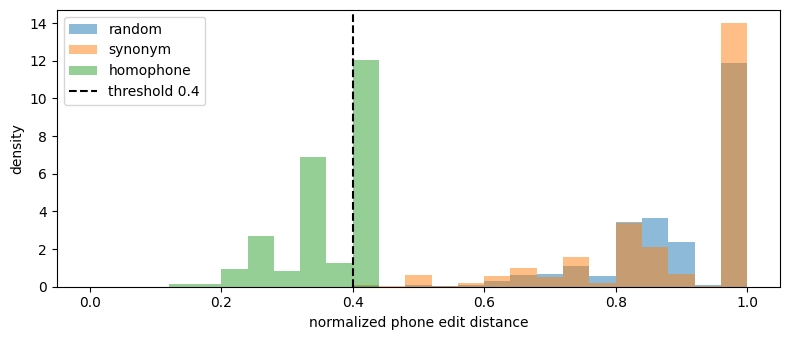

In [6]:
rng = np.random.default_rng(0)
distinct = list(info.keys())
random_d = []
for _ in range(50000):
    a, b = rng.choice(len(distinct), 2, replace=False)
    random_d.append(utils.phone_distance(info[distinct[a]][0], info[distinct[b]][0]))
random_d = np.array(random_d)

print(f"random pairs with distance <= 0.4: {(random_d <= 0.4).mean():.2%}")
print("random-pair percentiles:", {p: round(np.percentile(random_d, p), 2) for p in [0.1, 1, 5, 25, 50]})

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 26)
ax.hist(random_d, bins=bins, density=True, alpha=.5, label="random")
for t in ["synonym", "homophone"]:
    ax.hist(wordmap[wordmap.relation == t].distance, bins=bins, density=True, alpha=.5, label=t)
ax.axvline(config.PHONETIC_THRESHOLD, color="k", ls="--", label="threshold 0.4")
ax.set(xlabel="normalized phone edit distance", ylabel="density"); ax.legend()
plt.tight_layout()
fig.savefig(config.FIGS_DIR / "phone_distance_hist.png", dpi=150)